In [1]:
import os, json, math, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import make_grid as mg
importlib.reload(mg)        # pick up edits to make_grid.py without restarting the kernel
print("working in", os.getcwd())

working in /work/acd99/xbeach_sensitivity_slope


In [3]:
HM0 = 2.0                 # wave height (m)          -- same as the D50 study
TP = 10.0                 # peak period (s)          -- same as the D50 study
MAINANG = 225.0           # wave direction (deg, nautical): 45 deg from shore-normal
DX = 5.0                  # grid spacing (m)
FNYQ = 0.3                # spectrum cutoff (Hz)

N_CASES = 15
z0_values = np.round(np.linspace(20.0, 10.0, N_CASES), 3)        # offshore depth (m), evenly spaced
SLOPE_MODE = "uniform"    # "uniform": shoreface and surf zone share one slope (0.5 -> 0.25 deg)
                          # "shoreface": only the shoreface flattens; the surf zone keeps 0.5 deg
base_dir = "xbeach_cases"

slopes = [math.degrees(math.atan(mg.profile_slopes(z, SLOPE_MODE)[0])) for z in z0_values]
print(f"Hm0 = {HM0} m, Tp = {TP} s, mainang = {MAINANG} deg, dx = {DX} m, slope mode = {SLOPE_MODE}")
print(pd.DataFrame({"z0 (m)": z0_values, "slope (deg)": np.round(slopes, 3)}).to_string(index=False))

Hm0 = 2.0 m, Tp = 10.0 s, mainang = 225.0 deg, dx = 5.0 m, slope mode = uniform
 z0 (m)  slope (deg)
 20.000        0.500
 19.286        0.482
 18.571        0.464
 17.857        0.446
 17.143        0.429
 16.429        0.411
 15.714        0.393
 15.000        0.375
 14.286        0.357
 13.571        0.339
 12.857        0.321
 12.143        0.304
 11.429        0.286
 10.714        0.268
 10.000        0.250


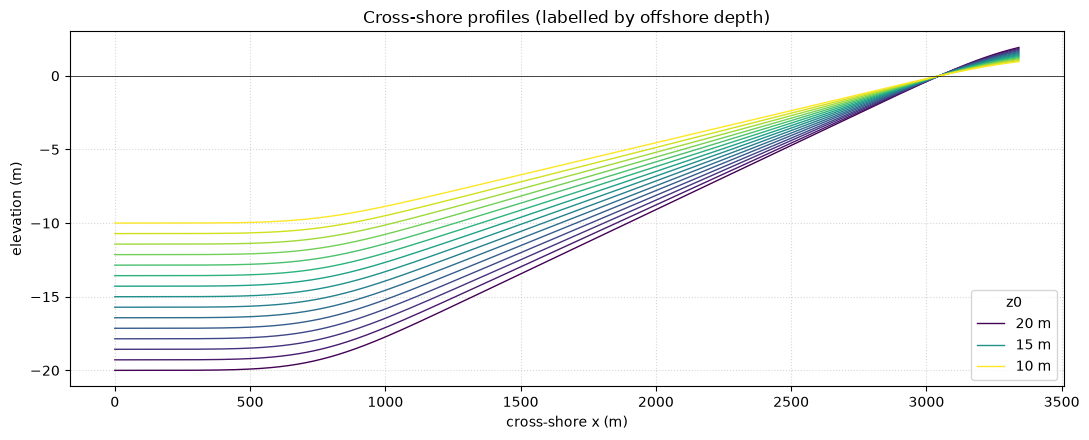

In [3]:
# ---------------- the 15 cross-shore profiles ----------------
fig, ax = plt.subplots(figsize=(11, 4.5))
cmap = plt.get_cmap("viridis")
for k, z0 in enumerate(z0_values):
    X, Y, Z = mg.bathymetry(DX, z0, SLOPE_MODE)
    ax.plot(X[0], Z[0], color=cmap(k / (N_CASES - 1)), lw=1, label=f"{z0:g} m" if k in (0, N_CASES // 2, N_CASES - 1) else None)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("cross-shore x (m)"); ax.set_ylabel("elevation (m)")
ax.set_title("Cross-shore profiles (labelled by offshore depth)")
ax.legend(title="z0"); ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout(); plt.show()

In [4]:
# ---------------- case folders ----------------
os.makedirs(base_dir, exist_ok=True)     # never wiped: existing cases and results are kept
info = mg.grid_info(DX)
case_dirs, rows, n_new = [], [], 0
for z0, slope in zip(z0_values, slopes):
    folder = os.path.join(base_dir, f"run_z0_{z0:05.2f}m")
    case_dirs.append(folder)
    os.makedirs(folder, exist_ok=True)
    grid_path = os.path.join(folder, "grid.json")
    if not os.path.exists(grid_path):
        with open(grid_path, "w") as f:
            json.dump({"dx": DX, "output": "mean", "z0": float(z0), "slope_mode": SLOPE_MODE,
                       "slope_deg": round(slope, 4), **info}, f)
    jonswap_path = os.path.join(folder, "jonswap.txt")
    if not os.path.exists(jonswap_path):
        wave_input = f"""Hm0 = {HM0:.2f}
Tp = {TP:.2f}
mainang = {MAINANG:.2f}
gammajsp = 20.0
s = 16.0
fnyq = {FNYQ}
eps = 0.01         
dryslp = 1.0       
"""
        with open(jonswap_path, "w") as f:
            f.write(wave_input)
        n_new += 1
    rows.append({"folder": folder, "z0": z0, "slope_deg": slope, "slope_mode": SLOPE_MODE, "hm0": HM0,
                 "tp": TP, "mainang": MAINANG, "dx": DX, **info})

assert len(set(case_dirs)) == len(case_dirs), "two depths round to the same folder name"
with open("case_list.txt", "w") as f:
    f.write("".join(f"{d}\n" for d in case_dirs))
pd.DataFrame(rows).to_csv("case_parameters.csv", index=False)
print(f"{len(case_dirs)} cases: {n_new} new, {len(case_dirs) - n_new} already existed")
print("Wrote case_list.txt and case_parameters.csv")

15 cases: 15 new, 0 already existed
Wrote case_list.txt and case_parameters.csv


In [5]:
# ---------------- compute plan ----------------
# From the surfbeat pilot runs (new build): ~35 min per case at 5 m typically, up to ~75 min on a
# slow node, peak memory ~4.5 GB at 5 m.
MIN_PER_CASE_5M = 60
MEM_GB_5M = 4.5

hours = MIN_PER_CASE_5M / 60 * (5.0 / DX) ** 3
t_lim = max(1, math.ceil(2 * hours))
mem = max(16, 2 ** math.ceil(math.log2(MEM_GB_5M * (5.0 / DX) ** 2 * 1.5)))
print(f"~{hours:.1f} h per case; all {N_CASES} cases run at once, so the batch takes about as long as one case")
print("\nSubmit from a terminal in this folder:")
print("mkdir -p logs")
print("python post_process.py --case_list case_list.txt --write_pending pending.txt")
print("sbatch --array=0-0 " f"--time={t_lim:02d}:00:00 --mem={mem}G xbeach_array.sbatch pending.txt      # test one case first")
print("python post_process.py --case_list case_list.txt --write_pending pending.txt")
print("sbatch --array=0-$(( $(wc -l < pending.txt) - 1 )) " f"--time={t_lim:02d}:00:00 --mem={mem}G xbeach_array.sbatch pending.txt")

~1.0 h per case; all 15 cases run at once, so the batch takes about as long as one case

Submit from a terminal in this folder:
mkdir -p logs
python post_process.py --case_list case_list.txt --write_pending pending.txt
sbatch --array=0-0 --time=02:00:00 --mem=16G xbeach_array.sbatch pending.txt      # test one case first
python post_process.py --case_list case_list.txt --write_pending pending.txt
sbatch --array=0-$(( $(wc -l < pending.txt) - 1 )) --time=02:00:00 --mem=16G xbeach_array.sbatch pending.txt


15 of 15 cases have results


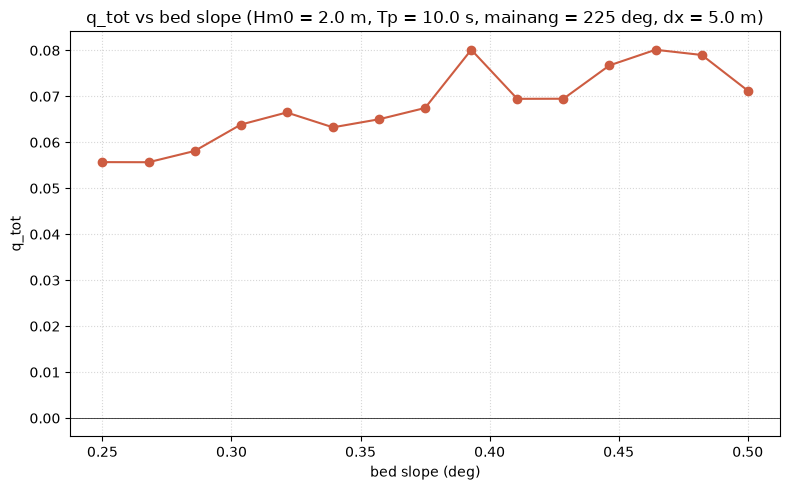

In [5]:
# ---------------- results: q_tot against bed slope (run once the batch has finished) ----------------
# Collect first, from a terminal:  python post_process.py --case_list case_list.txt --out q_tot_summary_slope.csv
if not os.path.exists("q_tot_summary_slope.csv"):
    print("No q_tot_summary_slope.csv yet: run the batch and collect the results first.")
else:
    res = pd.read_csv("q_tot_summary_slope.csv").sort_values("slope_deg")
    print(f"{len(res)} of {N_CASES} cases have results")
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(res["slope_deg"], res["q_tot"], "o-", color="#cd5c41")
    ax.set_xlabel("bed slope (deg)")
    ax.set_ylabel("q_tot")
    ax.axhline(0, color="k", lw=0.5)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.set_title(f"q_tot vs bed slope (Hm0 = {HM0} m, Tp = {TP} s, mainang = {MAINANG:g} deg, dx = {DX} m)")
    plt.tight_layout(); plt.show()